# Linaje de datos y análisis de impacto: grafos, ruta crítica y riesgo de propagación

**Perfil:** Liderazgo de datos y gobierno  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Cuando falla una fuente, ¿qué tableros se ven afectados? ¿Cuál es el orden correcto de ejecución? ¿Qué ruta determina la hora a la que están listos los reportes? ¿Qué nodos son puntos únicos de falla? ¿Qué tan fiable es el análisis de impacto si el linaje extraído es **incompleto**?

## Recorrido

1. Un catálogo de ~40 conjuntos de datos organizados por capas, con dependencias y tiempos de ejecución.
2. **Orden topológico** (Kahn) y **detección de ciclos** (DFS) con prueba de propiedades sobre cientos de grafos aleatorios.
3. **Linaje aguas arriba/abajo** por BFS, verificado contra la clausura transitiva (Warshall).
4. **Radio de impacto** de cada fuente y distribución de la criticidad.
5. **Ruta crítica** y holgura (CPM), verificada contra enumeración de caminos; qué acelerar y qué no.
6. **Planificación con recursos limitados**: cota de Graham.
7. **Puntos únicos de falla** y riesgo de propagación (exacto vs Monte Carlo), con efecto de la redundancia.
8. **Linaje incompleto**: cómo se degrada el análisis de impacto cuando faltan aristas.
9. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import itertools, collections

## 2. El catálogo

Se genera un DAG por capas: 6 fuentes crudas → 7 conjuntos limpios → 10 de *features* → 6 modelos → 6 reportes → 5 tableros (40 nodos). Cada nodo depende de 1–3 nodos de la capa inmediatamente anterior (y, con baja probabilidad, de uno dos capas atrás). Cada nodo tiene un tiempo de ejecución en minutos.

In [2]:
CAPAS = [("raw", 6), ("limpio", 7), ("feat", 10), ("modelo", 6), ("reporte", 6), ("tablero", 5)]
def generar_dag(seed, capas=CAPAS, salto=0.12):
    rg = np.random.default_rng(seed); nodos, capa_de = [], {}
    for ci, (pref, n) in enumerate(capas):
        for i in range(n): nodo = f"{pref}_{i + 1:02d}"; nodos.append(nodo); capa_de[nodo] = ci
    por_capa = {ci: [x for x in nodos if capa_de[x] == ci] for ci in range(len(capas))}
    aristas = set()
    for nodo in nodos:
        ci = capa_de[nodo]
        if ci == 0: continue
        previos = por_capa[ci - 1]; k = int(rg.integers(1, min(3, len(previos)) + 1))
        for p in rg.choice(previos, k, replace=False): aristas.add((str(p), nodo))
        if ci >= 2 and rg.random() < salto: aristas.add((str(rg.choice(por_capa[ci - 2])), nodo))
    dur = {x: float(np.round(rg.gamma(3.0, 4.0) + 2, 1)) for x in nodos}
    return nodos, sorted(aristas), dur, capa_de

NODOS, ARISTAS, DUR, CAPA = generar_dag(7)
HIJOS = collections.defaultdict(list); PADRES = collections.defaultdict(list)
for u, v in ARISTAS: HIJOS[u].append(v); PADRES[v].append(u)
print(f"{len(NODOS)} nodos, {len(ARISTAS)} aristas, duracion total {sum(DUR.values()):.0f} min")
print(pd.Series(CAPA).map(lambda c: CAPAS[c][0]).value_counts().reindex([c[0] for c in CAPAS]).to_string())

40 nodos, 77 aristas, duracion total 505 min
raw         6
limpio      7
feat       10
modelo      6
reporte     6
tablero     5


## 3. Orden topológico y detección de ciclos

**Kahn:** repetidamente se toma un nodo sin predecesores pendientes. Si quedan nodos sin procesar, hay un ciclo. **DFS con tres colores** devuelve además el ciclo concreto. Se prueban propiedades en 300 grafos aleatorios: (a) en un DAG, todo arco va de un nodo anterior a uno posterior en el orden; (b) tras inyectar un arco hacia atrás, ambos algoritmos detectan el ciclo y el ciclo devuelto es **realmente** un ciclo del grafo.

In [3]:
def kahn(nodos, aristas):
    indeg = {n: 0 for n in nodos}; hij = collections.defaultdict(list)
    for u, v in aristas: indeg[v] += 1; hij[u].append(v)
    cola = collections.deque(sorted(n for n in nodos if indeg[n] == 0)); orden = []
    while cola:
        u = cola.popleft(); orden.append(u)
        for v in sorted(hij[u]):
            indeg[v] -= 1
            if indeg[v] == 0: cola.append(v)
    return orden if len(orden) == len(nodos) else None

def buscar_ciclo(nodos, aristas):
    hij = collections.defaultdict(list)
    for u, v in aristas: hij[u].append(v)
    color = {n: 0 for n in nodos}; padre = {}
    def dfs(u):
        color[u] = 1
        for v in hij[u]:
            if color[v] == 0:
                padre[v] = u; c = dfs(v)
                if c: return c
            elif color[v] == 1:                                   # arco hacia atras: reconstruir el ciclo
                ciclo = [v]; x = u
                while x != v: ciclo.append(x); x = padre[x]
                return [v] + ciclo[1:][::-1] + [v]
        color[u] = 2; return None
    for n in nodos:
        if color[n] == 0:
            c = dfs(n)
            if c: return c
    return None

import sys as _s; _s.setrecursionlimit(10_000)
orden = kahn(NODOS, ARISTAS); pos = {n: i for i, n in enumerate(orden)}
print("Orden topologico valido:", all(pos[u] < pos[v] for u, v in ARISTAS), "| primeros 8:", orden[:8])
rg = np.random.default_rng(0); ok_orden = ok_ciclo = ok_real = n_ciclos = 0; R = 300
for s in range(R):
    nn, aa, _, cc = generar_dag(1000 + s, capas=[("a", 4), ("b", 5), ("c", 5), ("d", 3)])
    o = kahn(nn, aa); ok_orden += (o is not None) and all({n: i for i, n in enumerate(o)}[u] < {n: i for i, n in enumerate(o)}[v] for u, v in aa) and buscar_ciclo(nn, aa) is None
    # inyectar un arco hacia atras entre dos nodos conectados por un camino: de un descendiente a un ancestro
    u, v = aa[int(rg.integers(0, len(aa)))]; aa2 = aa + [(v, u)]; n_ciclos += 1
    c = buscar_ciclo(nn, aa2); ok_ciclo += (kahn(nn, aa2) is None) and (c is not None)
    ok_real += c is not None and c[0] == c[-1] and all((c[i], c[i + 1]) in set(aa2) for i in range(len(c) - 1))
print(f"DAG aleatorios con orden valido y sin ciclo: {ok_orden}/{R};  con ciclo inyectado: Kahn y DFS lo detectan {ok_ciclo}/{n_ciclos};  el ciclo devuelto es un ciclo real {ok_real}/{n_ciclos}")

Orden topologico valido: True | primeros 8: ['raw_01', 'raw_02', 'raw_03', 'raw_04', 'raw_05', 'raw_06', 'limpio_04', 'limpio_06']


DAG aleatorios con orden valido y sin ciclo: 300/300;  con ciclo inyectado: Kahn y DFS lo detectan 300/300;  el ciclo devuelto es un ciclo real 300/300


## 4. Linaje aguas arriba y aguas abajo

Con BFS se obtienen los **ancestros** (aguas arriba) y **descendientes** (aguas abajo) de un nodo. Se verifica contra la **clausura transitiva** por Warshall con matrices booleanas: $\text{cierre}[i,j]=1$ si hay un camino de $i$ a $j$.

In [4]:
def alcanzables(inicio, vecinos):
    vis, cola = set(), collections.deque([inicio])
    while cola:
        u = cola.popleft()
        for v in vecinos.get(u, []):
            if v not in vis: vis.add(v); cola.append(v)
    return vis

def cierre_warshall(nodos, aristas):
    idx = {n: i for i, n in enumerate(nodos)}; M = np.zeros((len(nodos), len(nodos)), bool)
    for u, v in aristas: M[idx[u], idx[v]] = True
    for k in range(len(nodos)): M |= np.outer(M[:, k], M[k, :])
    return M, idx

M, idx = cierre_warshall(NODOS, ARISTAS)
desc = {n: alcanzables(n, HIJOS) for n in NODOS}; anc = {n: alcanzables(n, PADRES) for n in NODOS}
coincide = all(desc[n] == {NODOS[j] for j in np.nonzero(M[idx[n]])[0]} for n in NODOS) and all(anc[n] == {NODOS[i] for i in np.nonzero(M[:, idx[n]])[0]} for n in NODOS)
print(f"BFS coincide con la clausura de Warshall en los {len(NODOS)} nodos: {coincide}")
t = "tablero_01"; print(f"\n'{t}' depende (aguas arriba) de {len(anc[t])} nodos: {sorted(anc[t])[:10]} ...")
f = "raw_01"; print(f"Si falla '{f}' se afectan {len(desc[f])} nodos; tableros afectados: {sorted(x for x in desc[f] if x.startswith('tablero'))}")

BFS coincide con la clausura de Warshall en los 40 nodos: True

'tablero_01' depende (aguas arriba) de 21 nodos: ['feat_02', 'feat_03', 'feat_09', 'feat_10', 'limpio_01', 'limpio_03', 'limpio_04', 'limpio_05', 'limpio_06', 'limpio_07'] ...
Si falla 'raw_01' se afectan 20 nodos; tableros afectados: ['tablero_01', 'tablero_02', 'tablero_03', 'tablero_04', 'tablero_05']


       capa  descendientes  ancestros  tableros_afectados
raw_03  raw             30          0                   5
raw_06  raw             28          0                   5
raw_05  raw             27          0                   5
raw_02  raw             26          0                   5
raw_04  raw             22          0                   5
raw_01  raw             20          0                   5

         descendientes     tableros_afectados    
                 mean max               mean max
capa                                            
raw           25.5000  30             5.0000   5
limpio        15.4000  21             4.6000   5
feat           5.1000  11             2.4000   5
modelo         4.5000   7             2.8000   4
reporte        1.8000   3             1.8000   3
tablero        0.0000   0             0.0000   0


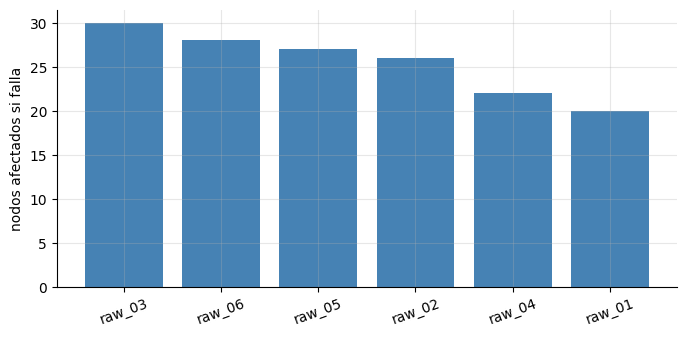

Lectura:
  La fuente mas critica es raw_03: su falla afecta 30 de 39 nodos y 5 de 5 tableros; la menos critica (raw_01) afecta 20.
  El radio de impacto medio de una fuente cruda es 25.5 nodos; el de un conjunto 'limpio' es 15.4: la dependencia se concentra aguas arriba.


In [5]:
rad = pd.DataFrame({"capa": [CAPAS[CAPA[n]][0] for n in NODOS], "descendientes": [len(desc[n]) for n in NODOS], "ancestros": [len(anc[n]) for n in NODOS],
                    "tableros_afectados": [sum(x.startswith("tablero") for x in desc[n]) for n in NODOS]}, index=NODOS)
fuentes = rad[rad.capa == "raw"].sort_values("descendientes", ascending=False)
print(fuentes.to_string())
por_capa = rad.groupby("capa", sort=False)[["descendientes", "tableros_afectados"]].agg(["mean", "max"]).round(1); print("\n", por_capa.to_string())
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(fuentes.index, fuentes["descendientes"], color="steelblue"); ax.set_ylabel("nodos afectados si falla"); plt.xticks(rotation=20); plt.show()
print("Lectura:")
print(f"  La fuente mas critica es {fuentes.index[0]}: su falla afecta {fuentes.iloc[0]['descendientes']} de {len(NODOS) - 1} nodos y {fuentes.iloc[0]['tableros_afectados']} de 5 tableros; la menos critica ({fuentes.index[-1]}) afecta {fuentes.iloc[-1]['descendientes']}.")
print(f"  El radio de impacto medio de una fuente cruda es {fuentes['descendientes'].mean():.1f} nodos; el de un conjunto 'limpio' es {rad[rad.capa == 'limpio']['descendientes'].mean():.1f}: la dependencia se concentra aguas arriba.")

## 5. Ruta crítica (CPM) y holgura

Cada nodo empieza cuando termina el último de sus predecesores. El **inicio más temprano** es $ES_v=\max_{u\to v}(ES_u+d_u)$ y el tiempo total (*makespan*) $=\max_v(ES_v+d_v)$. Hacia atrás se calcula el **inicio más tardío** $LS_v$ sin retrasar el total; la **holgura** es $LS_v-ES_v$ y la **ruta crítica** son los nodos con holgura 0. Se verifica el makespan contra la enumeración de **todos** los caminos en grafos pequeños.

In [6]:
def cpm(nodos, aristas, dur):
    orden = kahn(nodos, aristas); hij = collections.defaultdict(list); pad = collections.defaultdict(list)
    for u, v in aristas: hij[u].append(v); pad[v].append(u)
    ES = {n: 0.0 for n in nodos}
    for n in orden:
        for v in hij[n]: ES[v] = max(ES[v], ES[n] + dur[n])
    total = max(ES[n] + dur[n] for n in nodos); LS = {n: total - dur[n] for n in nodos}
    for n in reversed(orden):
        for v in hij[n]: LS[n] = min(LS[n], LS[v] - dur[n])
    return ES, LS, total

def makespan_enumerado(nodos, aristas, dur):
    hij = collections.defaultdict(list)
    for u, v in aristas: hij[u].append(v)
    mejor = 0.0
    def rec(u, acc):
        nonlocal mejor; acc += dur[u]; mejor = max(mejor, acc)
        for v in hij[u]: rec(v, acc)
    tienen_pad = {v for _, v in aristas}
    for n in nodos:
        if n not in tienen_pad: rec(n, 0.0)
    return mejor

ES, LS, TOTAL = cpm(NODOS, ARISTAS, DUR)
holg = pd.Series({n: LS[n] - ES[n] for n in NODOS}); critica = holg[holg.abs() < 1e-9].index.tolist()
ok = 0
for s in range(100):
    nn, aa, dd, _ = generar_dag(500 + s, capas=[("a", 3), ("b", 4), ("c", 4), ("d", 2)])
    ok += abs(cpm(nn, aa, dd)[2] - makespan_enumerado(nn, aa, dd)) < 1e-9
print(f"Makespan CPM = enumeracion de caminos en {ok}/100 grafos pequenos")
print(f"Makespan del catalogo: {TOTAL:.1f} min (suma de todas las duraciones: {sum(DUR.values()):.0f}); ruta critica: {len(critica)} nodos: {sorted(critica, key=lambda n: ES[n])}")

Makespan CPM = enumeracion de caminos en 100/100 grafos pequenos
Makespan del catalogo: 97.2 min (suma de todas las duraciones: 505); ruta critica: 6 nodos: ['raw_03', 'limpio_04', 'feat_04', 'modelo_04', 'reporte_04', 'tablero_05']


In [7]:
# acelerar un nodo: critico vs no critico
def con_dur(n, nueva): d = dict(DUR); d[n] = nueva; return cpm(NODOS, ARISTAS, d)[2]
nc = holg[holg > 5].sort_values(ascending=False).index[0]; cn = sorted(critica, key=lambda n: -DUR[n])[0]
print(f"Acelerar a la mitad el nodo critico '{cn}' ({DUR[cn]:.1f} -> {DUR[cn] / 2:.1f} min): makespan {TOTAL:.1f} -> {con_dur(cn, DUR[cn] / 2):.1f}  (maximo posible llevandolo a 0 min: {con_dur(cn, 0.0):.1f}; holgura minima de los no criticos: {holg[holg > 1e-9].min():.1f})")
print(f"Acelerar a la mitad el nodo NO critico '{nc}' (holgura {holg[nc]:.1f}, {DUR[nc]:.1f} -> {DUR[nc] / 2:.1f}): makespan {TOTAL:.1f} -> {con_dur(nc, DUR[nc] / 2):.1f}")
print(f"Retrasar '{nc}' hasta consumir su holgura (+{holg[nc]:.1f}): makespan {con_dur(nc, DUR[nc] + holg[nc]):.1f};  un minuto mas: {con_dur(nc, DUR[nc] + holg[nc] + 1):.1f}")
print(f"\nNodos con holgura 0: {len(critica)} de {len(NODOS)} ({len(critica) / len(NODOS):.0%}); holgura mediana de los demas: {holg[holg > 1e-9].median():.1f} min")

Acelerar a la mitad el nodo critico 'modelo_04' (25.3 -> 12.7 min): makespan 97.2 -> 96.9  (maximo posible llevandolo a 0 min: 96.9; holgura minima de los no criticos: 0.3)
Acelerar a la mitad el nodo NO critico 'feat_08' (holgura 55.1, 12.3 -> 6.2): makespan 97.2 -> 97.2
Retrasar 'feat_08' hasta consumir su holgura (+55.1): makespan 97.2;  un minuto mas: 98.2

Nodos con holgura 0: 6 de 40 (15%); holgura mediana de los demas: 14.2 min


## 6. Recursos limitados: cota de Graham

Con $k$ trabajadores y $W=\sum d_v$ de trabajo total, ningún plan puede ser más rápido que $\max(CP,\,W/k)$ donde $CP$ es la ruta crítica. La **planificación de lista** (cada vez que hay un trabajador libre, tomar una tarea lista) cumple la cota de Graham: $\text{makespan}\le W/k+CP\,(1-1/k)$. Se simula en 200 grafos aleatorios y se grafica el makespan del catálogo según $k$.

In [8]:
import heapq
def lista(nodos, aristas, dur, k, prioridad=None):
    pad = collections.defaultdict(set); hij = collections.defaultdict(list); fin = {}
    for u, v in aristas: pad[v].add(u); hij[u].append(v)
    pend = {n: len(pad[n]) for n in nodos}; listas = [(-(prioridad or {}).get(n, 0), n) for n in nodos if pend[n] == 0]; heapq.heapify(listas)
    libres = k; t = 0.0; corriendo = []; hechos = 0
    while hechos < len(nodos):
        while libres and listas:
            _, n = heapq.heappop(listas); heapq.heappush(corriendo, (t + dur[n], n)); libres -= 1
        t, n = heapq.heappop(corriendo); libres += 1; hechos += 1; fin[n] = t
        for v in hij[n]:
            pend[v] -= 1
            if pend[v] == 0: heapq.heappush(listas, (-(prioridad or {}).get(v, 0), v))
    return t

def cola_critica(nodos, aristas, dur):                          # prioridad = longitud del camino mas largo hasta el final (HLFET)
    hij = collections.defaultdict(list)
    for u, v in aristas: hij[u].append(v)
    L = {}
    for n in reversed(kahn(nodos, aristas)): L[n] = dur[n] + max((L[v] for v in hij[n]), default=0.0)
    return L

viol = 0; razones = []
for s in range(200):
    nn, aa, dd, _ = generar_dag(3000 + s, capas=[("a", 5), ("b", 6), ("c", 6), ("d", 3)]); W = sum(dd.values()); cp = cpm(nn, aa, dd)[2]
    for k in (2, 3, 5):
        m = lista(nn, aa, dd, k); li = max(cp, W / k); ls = W / k + cp * (1 - 1 / k)
        viol += (m < li - 1e-9) or (m > ls + 1e-9); razones.append(m / li)
print(f"Violaciones de la cota inferior/superior de Graham en 600 simulaciones: {viol};  razon makespan/cota inferior: media {np.mean(razones):.3f}, max {np.max(razones):.3f}")
W_ = sum(DUR.values()); P = cola_critica(NODOS, ARISTAS, DUR)
filas = [{"k_trabajadores": k, "makespan_FIFO": lista(NODOS, ARISTAS, DUR, k), "makespan_HLFET": lista(NODOS, ARISTAS, DUR, k, P), "cota_inferior": max(TOTAL, W_ / k)} for k in (1, 2, 3, 4, 6, 8, 16)]
gr = pd.DataFrame(filas).set_index("k_trabajadores"); gr.round(1)

Violaciones de la cota inferior/superior de Graham en 600 simulaciones: 0;  razon makespan/cota inferior: media 1.055, max 1.337


,makespan_FIFO,makespan_HLFET,cota_inferior
k_trabajadores,,,
1,504.9000,504.9000,504.9000
2,256.3000,253.0000,252.4000
3,173.6000,169.3000,168.3000
4,136.1000,128.8000,126.2000
6,100.7000,97.2000,97.2000
8,97.2000,97.2000,97.2000
16,97.2000,97.2000,97.2000


In [9]:
sat = gr.index[(gr["makespan_HLFET"] - TOTAL).abs() < 1e-6].min()
print("Lectura:")
print(f"  Con 1 trabajador el plan dura {gr.loc[1, 'makespan_HLFET']:.0f} min (todo el trabajo); con {sat} trabajadores se alcanza la ruta critica ({TOTAL:.1f} min): mas recursos no ayudan despues, porque la cadena de dependencias manda.")
print(f"  Priorizar por camino restante (HLFET) mejora o iguala la regla FIFO: ahorro maximo {int((gr['makespan_FIFO'] - gr['makespan_HLFET']).max())} min con un numero intermedio de trabajadores.")

Lectura:
  Con 1 trabajador el plan dura 505 min (todo el trabajo); con 6 trabajadores se alcanza la ruta critica (97.2 min): mas recursos no ayudan despues, porque la cadena de dependencias manda.
  Priorizar por camino restante (HLFET) mejora o iguala la regla FIFO: ahorro maximo 7 min con un numero intermedio de trabajadores.


## 7. Puntos únicos de falla y propagación de riesgo

Un **punto único de falla** (SPOF) de un tablero es un nodo cuya salida del grafo deja al tablero sin **ninguna** ruta desde las fuentes. Se calcula quitando cada nodo y verificando alcanzabilidad.

Con semántica **OR** (un nodo falla si falla *cualquiera* de sus entradas) cada fuente falla con probabilidad $p$ y cada transformación con $q$. La probabilidad de que falle un tablero se calcula por **Monte Carlo** y se verifica contra el **cálculo exacto** (enumeración de los 2^n estados de un sub-grafo pequeño). La **redundancia** (semántica AND: el nodo funciona si funciona *alguna* de sus entradas) se compara en un caso.

In [10]:
def spof(tab, nodos, aristas):
    fuentes = [n for n in nodos if CAPA[n] == 0]; res = []
    for x in nodos:
        if x == tab or x in fuentes and False: continue
        hij = collections.defaultdict(list)
        for u, v in aristas:
            if u != x and v != x: hij[u].append(v)
        llega = set().union(*[alcanzables(f, hij) | {f} for f in fuentes if f != x]) if any(f != x for f in fuentes) else set()
        if tab not in llega: res.append(x)
    return res

tabs = [n for n in NODOS if n.startswith("tablero")]
sp = {t_: spof(t_, NODOS, ARISTAS) for t_ in tabs}
tab_sp = pd.DataFrame({"n_SPOF": {t_: len(v) for t_, v in sp.items()}, "SPOF (muestra)": {t_: ", ".join(v[:4]) for t_, v in sp.items()}}); print(tab_sp.to_string())

            n_SPOF SPOF (muestra)
tablero_01       0               
tablero_02       0               
tablero_03       0               
tablero_04       0               
tablero_05       1     reporte_04


In [11]:
def sim_falla(nodos, aristas, p_raw, p_tr, R, rg, destino, redundante=frozenset()):
    # semantica OR por defecto; en 'redundante' el nodo falla solo si fallan TODAS sus entradas (AND)
    orden = kahn(nodos, aristas); pad = collections.defaultdict(list)
    for u, v in aristas: pad[v].append(u)
    idx = {n: i for i, n in enumerate(nodos)}; F = np.zeros((R, len(nodos)), bool)
    for n in orden:
        propio = rg.random(R) < (p_raw if CAPA[n] == 0 else p_tr)
        if not pad[n]: F[:, idx[n]] = propio
        else:
            ent = np.stack([F[:, idx[u]] for u in pad[n]], axis=1)
            F[:, idx[n]] = propio | (ent.all(axis=1) if n in redundante else ent.any(axis=1))
    return F[:, idx[destino]].mean()

# verificacion exacta en un sub-grafo pequeno (enumeracion de 2^n)
sub_n, sub_a, sub_d, _ = generar_dag(11, capas=[("raw", 2), ("limpio", 2), ("feat", 2), ("tablero", 1)])
CAPA_bak = dict(CAPA); CAPA.update({n: 0 if n.startswith("raw") else 1 for n in sub_n})
def exacta(nodos, aristas, p_raw, p_tr, destino):
    orden = kahn(nodos, aristas); pad = collections.defaultdict(list)
    for u, v in aristas: pad[v].append(u)
    total = 0.0
    for estado in itertools.product([0, 1], repeat=len(nodos)):
        prob = 1.0; propio = {}
        for n, e in zip(nodos, estado): pr = p_raw if CAPA[n] == 0 else p_tr; propio[n] = e; prob *= pr if e else 1 - pr
        F = {}
        for n in orden: F[n] = propio[n] or any(F[u] for u in pad[n])
        total += prob * F[destino]
    return total
dest = "tablero_01"; pe = exacta(sub_n, sub_a, 0.03, 0.01, dest); pm = sim_falla(sub_n, sub_a, 0.03, 0.01, 400_000, np.random.default_rng(3), dest)
print(f"Sub-grafo ({len(sub_n)} nodos, {len(sub_a)} aristas): P(falla tablero) exacta = {pe:.5f}, Monte Carlo = {pm:.5f}")
CAPA.clear(); CAPA.update(CAPA_bak)

Sub-grafo (7 nodos, 8 aristas): P(falla tablero) exacta = 0.08705, Monte Carlo = 0.08600


In [12]:
rg = np.random.default_rng(8); filas = []
for p_raw, p_tr in ((0.01, 0.005), (0.03, 0.01), (0.05, 0.02)):
    filas.append({"p_fuente": p_raw, "p_transformacion": p_tr, **{t_: sim_falla(NODOS, ARISTAS, p_raw, p_tr, 60_000, rg, t_) for t_ in tabs[:3]}, f"ancestros_de_{tabs[0]}": len(anc[tabs[0]])})
pf = pd.DataFrame(filas).set_index(["p_fuente", "p_transformacion"]); print(pf.round(4).to_string())
# redundancia: el primer tablero lee de dos reportes; si se hacen redundantes (AND) cae el riesgo
t0 = tabs[0]; red = frozenset([t0])
base = sim_falla(NODOS, ARISTAS, 0.03, 0.01, 200_000, np.random.default_rng(1), t0); con_red = sim_falla(NODOS, ARISTAS, 0.03, 0.01, 200_000, np.random.default_rng(1), t0, red)
print(f"\nP(falla {t0}) OR: {base:.4f};  con entradas redundantes (AND): {con_red:.4f}  (reduccion {1 - con_red / base:.0%}, con {len(PADRES[t0])} entradas)")

                           tablero_01  tablero_02  tablero_03  ancestros_de_tablero_01
p_fuente p_transformacion                                                             
0.0100   0.0050                0.1293      0.1488      0.1493                       21
0.0300   0.0100                0.2926      0.3171      0.3207                       21
0.0500   0.0200                0.4625      0.5081      0.5077                       21



P(falla tablero_01) OR: 0.2918;  con entradas redundantes (AND): 0.1801  (reduccion 38%, con 2 entradas)


In [13]:
print("Lectura:")
print(f"  El sub-grafo exacto da {pe:.5f} y el Monte Carlo {pm:.5f}: el simulador reproduce el calculo exacto (error relativo {abs(pm / pe - 1):.1%}).")
print(f"  Un tablero con muchos ancestros falla con mas probabilidad: {pf.iloc[1, 0]:.3f} para {tabs[0]} con p_fuente=3% y p_transformacion=1% (frente a la probabilidad de un solo nodo: 1%-3%). Cada capa de dependencias suma riesgo.")
print(f"  Hacer redundantes las entradas de {t0} baja el riesgo en {1 - con_red / base:.0%} aunque el riesgo propio del nodo (1%) queda: el piso es el nodo mismo.")
print(f"  SPOFs (sin contar al propio tablero): entre {tab_sp.n_SPOF.min()} y {tab_sp.n_SPOF.max()} por tablero; todos son ancestros: eliminar cualquier otro nodo deja al tablero con alguna ruta desde las fuentes.")

Lectura:
  El sub-grafo exacto da 0.08705 y el Monte Carlo 0.08600: el simulador reproduce el calculo exacto (error relativo 1.2%).
  Un tablero con muchos ancestros falla con mas probabilidad: 0.293 para tablero_01 con p_fuente=3% y p_transformacion=1% (frente a la probabilidad de un solo nodo: 1%-3%). Cada capa de dependencias suma riesgo.
  Hacer redundantes las entradas de tablero_01 baja el riesgo en 38% aunque el riesgo propio del nodo (1%) queda: el piso es el nodo mismo.
  SPOFs (sin contar al propio tablero): entre 0 y 1 por tablero; todos son ancestros: eliminar cualquier otro nodo deja al tablero con alguna ruta desde las fuentes.


## 8. Linaje incompleto: ¿qué tan fiable es el análisis de impacto?

En la práctica el linaje se **extrae** (de logs de SQL, orquestadores) y siempre falta algo: scripts ad-hoc, hojas de cálculo, notebooks. Se simula la omisión aleatoria de una fracción $\phi$ de aristas y se mide el **recall del radio de impacto**: de los descendientes verdaderos de cada fuente, ¿qué fracción se encuentra con el linaje incompleto? También se mide el efecto de **aristas falsas** (precisión).

In [14]:
def recall_impacto(aristas_obs, fuentes, verdad_desc):
    hij = collections.defaultdict(list)
    for u, v in aristas_obs: hij[u].append(v)
    rec, prec = [], []
    for f in fuentes:
        d = alcanzables(f, hij); v = verdad_desc[f]; rec.append(len(d & v) / max(len(v), 1)); prec.append(len(d & v) / max(len(d), 1))
    return np.mean(rec), np.mean(prec), np.min(rec)

fuentes_l = [n for n in NODOS if CAPA[n] == 0]; verdad = {f: desc[f] for f in fuentes_l}
rg = np.random.default_rng(14); filas = []
for fi in (0.0, 0.05, 0.10, 0.20, 0.30, 0.50):
    rs, mins = [], []
    for _ in range(300):
        obs = [a for a in ARISTAS if rg.random() >= fi]; r_, _, mn = recall_impacto(obs, fuentes_l, verdad); rs.append(r_); mins.append(mn)
    filas.append({"aristas_omitidas": fi, "recall_medio_impacto": np.mean(rs), "recall_peor_fuente_medio": np.mean(mins), "P5_recall": np.percentile(rs, 5)})
inc = pd.DataFrame(filas).set_index("aristas_omitidas")
falsos = []
for fa in (0.0, 0.05, 0.10, 0.20):
    ps = []
    for _ in range(300):
        extra = []
        for _ in range(int(fa * len(ARISTAS))):                      # arista falsa hacia adelante entre dos nodos al azar
            a, b = rg.choice(NODOS, 2, replace=False); a, b = (a, b) if CAPA[a] < CAPA[b] else (b, a)
            if CAPA[a] < CAPA[b]: extra.append((str(a), str(b)))
        _, p_, _ = recall_impacto(ARISTAS + extra, fuentes_l, verdad); ps.append(p_)
    falsos.append({"aristas_falsas": fa, "precision_media_impacto": np.mean(ps)})
fal = pd.DataFrame(falsos).set_index("aristas_falsas"); print(inc.round(3).to_string()); print(); print(fal.round(3).to_string())

                  recall_medio_impacto  recall_peor_fuente_medio  P5_recall
aristas_omitidas                                                           
0.0000                          1.0000                    1.0000     1.0000
0.0500                          0.9340                    0.7960     0.8370
0.1000                          0.8620                    0.6560     0.7250
0.2000                          0.7180                    0.4400     0.5530
0.3000                          0.5340                    0.2300     0.3140
0.5000                          0.2510                    0.0410     0.1250

                precision_media_impacto
aristas_falsas                         
0.0000                           1.0000
0.0500                           0.9930
0.1000                           0.9850
0.2000                           0.9670


In [15]:
print("Lectura:")
print(f"  Con 10% de aristas omitidas el analisis de impacto encuentra en promedio {inc.loc[0.10, 'recall_medio_impacto']:.0%} de lo realmente afectado; con 30%, {inc.loc[0.30, 'recall_medio_impacto']:.0%}. Peor fuente (media): {inc.loc[0.30, 'recall_peor_fuente_medio']:.0%}.")
print(f"  La perdida es MAS que proporcional porque un arco omitido corta todos los caminos que pasan por el: el recall cae de {inc.loc[0.10, 'recall_medio_impacto']:.2f} a {inc.loc[0.50, 'recall_medio_impacto']:.2f} cuando faltan la mitad.")
print(f"  Con 20% de aristas falsas la precision solo baja a {fal.loc[0.20, 'precision_media_impacto']:.0%}: el grafo ya esta muy conectado aguas abajo y una arista extra rara vez anade nodos nuevos. Con 20% de aristas OMITIDAS, el recall cae a {inc.loc[0.20, 'recall_medio_impacto']:.0%}.")
print("  Asimetria: en este grafo el error costoso es omitir dependencias (se subestima el impacto), no inventarlas; por eso conviene un linaje conservador (que incluya dependencias dudosas).")
print("  Moraleja: la completitud del linaje es una metrica de calidad en si; medirla con una muestra de verificaciones manuales es mas informativo que contar aristas.")

Lectura:
  Con 10% de aristas omitidas el analisis de impacto encuentra en promedio 86% de lo realmente afectado; con 30%, 53%. Peor fuente (media): 23%.
  La perdida es MAS que proporcional porque un arco omitido corta todos los caminos que pasan por el: el recall cae de 0.86 a 0.25 cuando faltan la mitad.
  Con 20% de aristas falsas la precision solo baja a 97%: el grafo ya esta muy conectado aguas abajo y una arista extra rara vez anade nodos nuevos. Con 20% de aristas OMITIDAS, el recall cae a 72%.
  Asimetria: en este grafo el error costoso es omitir dependencias (se subestima el impacto), no inventarlas; por eso conviene un linaje conservador (que incluya dependencias dudosas).
  Moraleja: la completitud del linaje es una metrica de calidad en si; medirla con una muestra de verificaciones manuales es mas informativo que contar aristas.


## 9. Pruebas automáticas

In [16]:
# 9.1 orden topologico y ciclos
assert ok_orden == 300 and ok_ciclo == 300 and ok_real == 300 and all(pos[u] < pos[v] for u, v in ARISTAS)
# 9.2 BFS = clausura transitiva
assert coincide and all(desc[n].isdisjoint(anc[n]) for n in NODOS)
# 9.3 impacto: las fuentes tienen mas descendientes que los tableros (0), y los tableros no tienen descendientes
assert (rad[rad.capa == "tablero"]["descendientes"] == 0).all() and (rad[rad.capa == "raw"]["ancestros"] == 0).all() and fuentes["descendientes"].iloc[0] >= fuentes["descendientes"].iloc[-1]
# 9.4 CPM: enumeracion de caminos, holgura >= 0, acelerar un nodo no critico no cambia el total
assert ok == 100 and (holg > -1e-9).all() and len(critica) >= 2
assert abs(con_dur(nc, DUR[nc] / 2) - TOTAL) < 1e-9 and con_dur(cn, DUR[cn] / 2) < TOTAL - 1e-9
assert abs(con_dur(nc, DUR[nc] + holg[nc]) - TOTAL) < 1e-6 and con_dur(nc, DUR[nc] + holg[nc] + 1) > TOTAL + 0.99
# 9.5 Graham y recursos
assert viol == 0 and gr["makespan_HLFET"].is_monotonic_decreasing and abs(gr.loc[1, "makespan_HLFET"] - W_) < 1e-6 and abs(gr.loc[16, "makespan_HLFET"] - TOTAL) < 1e-6
assert (gr["makespan_HLFET"] >= gr["cota_inferior"] - 1e-9).all()
# 9.6 riesgo: Monte Carlo = exacto; redundancia reduce
assert abs(pm - pe) / pe < 0.03 and con_red < base and pf.iloc[0, 0] < pf.iloc[1, 0] < pf.iloc[2, 0]
assert all(set(sp[t_]) <= anc[t_] for t_ in tabs) and all(CAPA[x] < CAPA[t_] for t_ in tabs for x in sp[t_])
# 9.7 linaje incompleto: recall decrece con la omision; precision decrece con las aristas falsas
assert inc["recall_medio_impacto"].is_monotonic_decreasing and abs(inc.loc[0.0, "recall_medio_impacto"] - 1) < 1e-12 and inc.loc[0.30, "recall_medio_impacto"] < 0.85
assert fal["precision_media_impacto"].is_monotonic_decreasing and abs(fal.loc[0.0, "precision_media_impacto"] - 1) < 1e-12
assert (1 - fal.loc[0.20, "precision_media_impacto"]) < 0.5 * (1 - inc.loc[0.20, "recall_medio_impacto"])      # asimetria: omitir cuesta mas que inventar
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Orden y ciclos | Kahn y DFS se verifican con propiedades sobre cientos de grafos; el ciclo devuelto es real | Validar el linaje con detección de ciclos antes de planificar |
| Impacto | Unas pocas fuentes concentran el radio de impacto | Priorizar monitoreo y SLA en esas fuentes |
| Ruta crítica | Solo los nodos sin holgura determinan el tiempo total; acelerar los demás no sirve | Optimizar la ruta crítica y vigilar la holgura de los casi críticos |
| Recursos | Con trabajadores suficientes se alcanza la ruta crítica; más no ayuda | Dimensionar el paralelismo con la cota de Graham |
| Riesgo de propagación | Cada capa suma riesgo; la redundancia lo reduce hasta el piso del propio nodo | Añadir redundancia donde el nodo tiene muchas dependencias únicas |
| Linaje incompleto | Omitir aristas reduce el recall del impacto más que proporcionalmente; las aristas falsas casi no reducen la precisión en un grafo denso | Preferir un linaje conservador y medir su completitud con verificaciones manuales |

**Límites que no deben ocultarse**

- El DAG es sintético por capas; los grafos reales tienen más ciclos aparentes (reprocesos), granularidad de columnas y dependencias temporales.
- La semántica OR/AND de fallas es una simplificación; en la práctica hay degradación parcial y datos obsoletos que siguen sirviendo.
- Las duraciones son deterministas; con tiempos aleatorios la ruta crítica cambia entre ejecuciones.
- La omisión de aristas es aleatoria e independiente; en realidad se concentra en los procesos menos documentados (hojas de cálculo, scripts ad-hoc).